# **01- SQuAD 2.0 exploration and article-level splits**

**Goal**: know the data before modelling it.

## **1. Create the article-level split**

In [6]:
import os, sys
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")    
sys.path.insert(0, "src")
print(Path.cwd())

d:\Aya\study\MDS2\NLP\Project\script


In [7]:
!{sys.executable} experiments/m1_make_splits.py

Training examples whose answer offsets do not match the context: 0
Articles shared with the official dev (test) set: 0
               train: {'questions': 117387, 'articles': 398, 'paragraphs': 17134, 'unanswerable': 38875, 'unanswerable_share': 0.3311695502909181}
          validation: {'questions': 12932, 'articles': 44, 'paragraphs': 1895, 'unanswerable': 4623, 'unanswerable_share': 0.357485307763687}
 test (official dev): {'questions': 11873, 'articles': 35, 'paragraphs': 1204, 'unanswerable': 5945, 'unanswerable_share': 0.5007159100480081}
Saved split definition to configs/squad_v2_article_splits.json


## **2.Load the three splits**

In [8]:
from qa.data import load_squad_v2, load_split_definition

squad = load_squad_v2()
split_definition = load_split_definition("configs/squad_v2_article_splits.json")
validation_titles = set(split_definition["validation_titles"])

splits = {
    "train": squad["train"].filter(lambda ex: ex["title"] not in validation_titles),
    "validation": squad["train"].filter(lambda ex: ex["title"] in validation_titles),
    "test": squad["validation"],
}
print(splits["train"][0])

Filter: 100%|██████████| 130319/130319 [00:00<00:00, 252236.96 examples/s]

{'id': '56be85543aeaaa14008c9063', 'title': 'Beyoncé', 'context': 'Beyoncé Giselle Knowles-Carter (/biːˈjɒnseɪ/ bee-YON-say) (born September 4, 1981) is an American singer, songwriter, record producer and actress. Born and raised in Houston, Texas, she performed in various singing and dancing competitions as a child, and rose to fame in the late 1990s as lead singer of R&B girl-group Destiny\'s Child. Managed by her father, Mathew Knowles, the group became one of the world\'s best-selling girl groups of all time. Their hiatus saw the release of Beyoncé\'s debut album, Dangerously in Love (2003), which established her as a solo artist worldwide, earned five Grammy Awards and featured the Billboard Hot 100 number-one singles "Crazy in Love" and "Baby Boy".', 'question': 'When did Beyonce start becoming popular?', 'answers': {'text': ['in the late 1990s'], 'answer_start': [269]}}


## **3. Headline counts**

In [9]:
import pandas as pd
from qa.exploration import summarise_split

summary = pd.DataFrame({name: summarise_split(split) for name, split in splits.items()}).T
summary

,questions,articles,paragraphs,unanswerable,unanswerable_share
train,117387.0,398.0,17134.0,38875.0,0.331170
validation,12932.0,44.0,1895.0,4623.0,0.357485
test,11873.0,35.0,1204.0,5945.0,0.500716


## **4. Paragraph lengths**

count    17134.000000
mean       119.711568
std         51.385749
min         20.000000
25%         89.000000
50%        110.000000
75%        143.000000
max        677.000000
dtype: float64


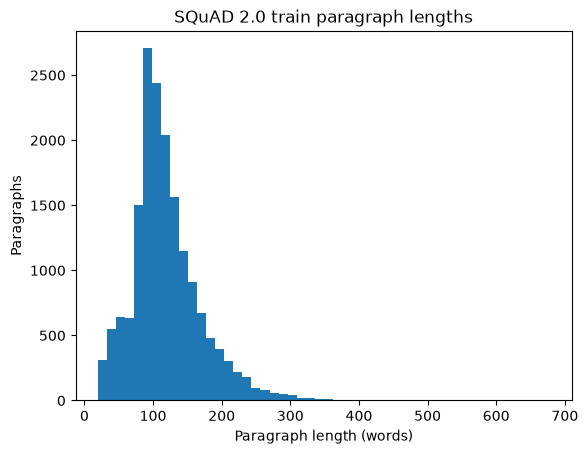

In [10]:
import matplotlib.pyplot as plt
from qa.data import build_passage_pool
from qa.exploration import simple_word_tokens

passages, _ = build_passage_pool(splits["train"])
paragraph_lengths = pd.Series([len(simple_word_tokens(p["context"])) for p in passages])
print(paragraph_lengths.describe())

plt.hist(paragraph_lengths, bins=50)
plt.xlabel("Paragraph length (words)")
plt.ylabel("Paragraphs")
plt.title("SQuAD 2.0 train paragraph lengths")
plt.show()

## **5. Paragraphs per article**

In [11]:
paragraphs_per_article = pd.Series([p["title"] for p in passages]).value_counts()
paragraphs_per_article.describe()

count    398.000000
mean      43.050251
std       21.547966
min       10.000000
25%       26.000000
50%       37.000000
75%       56.000000
max      149.000000
Name: count, dtype: float64

## **6. Question types**

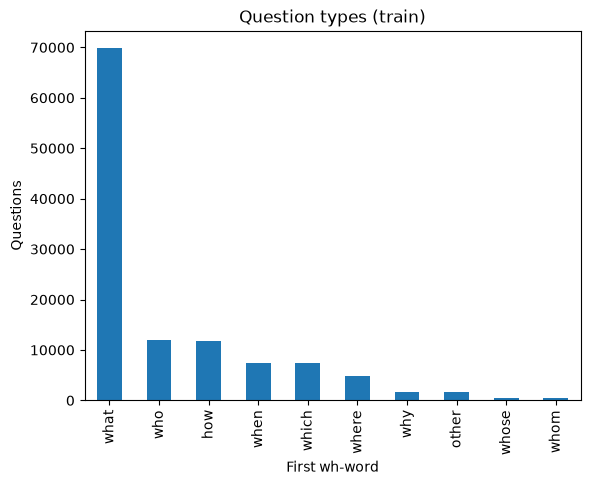

what     0.595
who      0.102
how      0.101
when     0.063
which    0.063
where    0.040
why      0.015
other    0.014
whose    0.004
whom     0.004
dtype: float64

In [12]:
from qa.exploration import count_question_types

question_types = pd.Series(count_question_types(splits["train"])).sort_values(ascending=False)
question_types.plot.bar(xlabel="First wh-word", ylabel="Questions", title="Question types (train)")
plt.show()
(question_types / question_types.sum()).round(3)

## **7. Answer lengths**

count    78512.000000
mean         3.305902
std          3.467766
min          0.000000
25%          1.000000
50%          2.000000
75%          4.000000
max         43.000000
dtype: float64


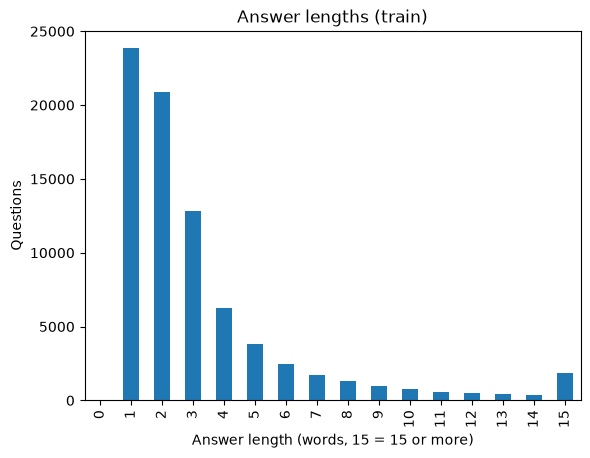

In [13]:
from qa.data import is_answerable

answer_lengths = pd.Series([
    len(simple_word_tokens(ex["answers"]["text"][0]))
    for ex in splits["train"] if is_answerable(ex)
])
print(answer_lengths.describe())
answer_lengths.clip(upper=15).value_counts().sort_index().plot.bar(
    xlabel="Answer length (words, 15 = 15 or more)", ylabel="Questions", title="Answer lengths (train)")
plt.show()

## **8. Question-paragraph word overlap**

              count      mean       std  min  25%       50%       75%  max
answerable                                                                
False       38875.0  0.640609  0.228471  0.0  0.5  0.666667  0.800000  1.0
True        78512.0  0.670421  0.228247  0.0  0.5  0.666667  0.833333  1.0


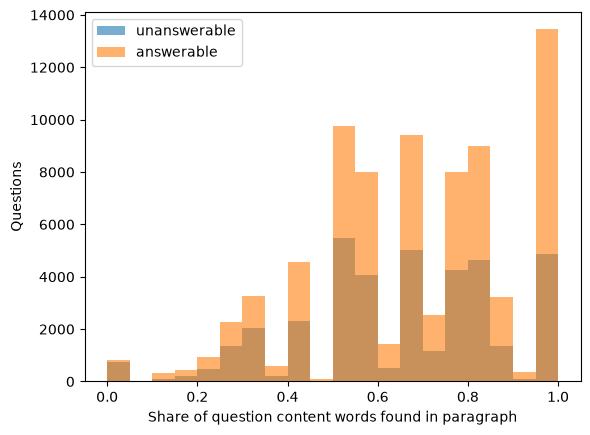

In [14]:
from qa.exploration import question_context_overlap

overlap = pd.DataFrame({
    "overlap": [question_context_overlap(ex["question"], ex["context"]) for ex in splits["train"]],
    "answerable": [is_answerable(ex) for ex in splits["train"]],
})
print(overlap.groupby("answerable")["overlap"].describe())
for answerable, group in overlap.groupby("answerable"):
    plt.hist(group["overlap"], bins=20, alpha=0.6, label="answerable" if answerable else "unanswerable")
plt.xlabel("Share of question content words found in paragraph")
plt.ylabel("Questions")
plt.legend()
plt.show()

## **9. Read real examples**

In [15]:
answerable_examples = splits["train"].filter(is_answerable).shuffle(seed=0).select(range(3))
unanswerable_examples = splits["train"].filter(lambda ex: not is_answerable(ex)).shuffle(seed=0).select(range(3))
for ex in list(answerable_examples) + list(unanswerable_examples):
    print("Q:", ex["question"])
    print("A:", ex["answers"]["text"] or "<no answer>")
    print("Context:", ex["context"][:300], "...\n")

Filter: 100%|██████████| 117387/117387 [00:02<00:00, 51477.69 examples/s]

Q: What was the fertility rate of Hyderabad according to a 2005 survey?
A: ['1.8']
Context: In the 2005 National Family Health Survey, it was reported that the city's total fertility rate is 1.8,:47 which is below the replacement rate. Only 61% of children had been provided with all basic vaccines (BCG, measles and full courses of polio and DPT), fewer than in all other surveyed cities exc ...

Q: Near what body of water is St. John's located by?
A: ['Atlantic Ocean']
Context: St. John's is located along the coast of the Atlantic Ocean, on the northeast of the Avalon Peninsula in southeast Newfoundland. The city covers an area of 446.04 square kilometres (172.22 sq mi) and is the most easterly city in North America, excluding Greenland; it is 295 miles (475 km) closer to  ...

Q: How many components are used in an assessment?
A: ['there are three components of sexual orientation']
Context: Research focusing on sexual orientation uses scales of assessment to identify who belongs in whic